# DeepPCB -> labelled tile dataset

First notebook of the **gated tile cascade** project (ECE 690OD). It does four things:

1. downloads **DeepPCB** (1,500 aligned template/test pairs, 640x640, binarized);
2. plots the **defect-size histogram per class**, which is what justifies the tile/stride choice;
3. sweeps candidate tile grids and reports the **recall ceiling** each one implies;
4. builds the **labelled tile dataset** with ignore masks and an image-level train/val split.

Open it in Colab straight from GitHub, or run it locally from the repo root.
No GPU needed - this notebook is pure data prep.

## 0. Setup

In [1]:
import os, sys, subprocess

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/vsubacius/PCBerrorDetection.git'
BRANCH   = 'main'

if IN_COLAB:
    if not os.path.isdir('PCBerrorDetection'):
        subprocess.run(['git','clone','--branch',BRANCH,REPO_URL], check=True)
    os.chdir('PCBerrorDetection')
    subprocess.run([sys.executable,'-m','pip','install','-q','numpy','pillow','matplotlib'], check=True)

# All paths below are relative to the repo root, so find it and chdir there
# (Jupyter starts in notebooks/, Colab in the clone we just made).
root = os.path.abspath(os.getcwd())
while not os.path.isfile(os.path.join(root, 'CLAUDE.md')):
    parent = os.path.dirname(root)
    if parent == root:
        raise RuntimeError('repo root (the directory holding CLAUDE.md) not found')
    root = parent
os.chdir(root)
sys.path.insert(0, os.path.join(root, 'data'))

import numpy as np
import matplotlib.pyplot as plt

import deeppcb, build_tiles, grid_sweep
from tiling import TileGrid, label_tiles, is_clean, box_overlap_fracs
from tile_dataset import TileData, AugmentConfig

print('python', sys.version.split()[0], '| colab', IN_COLAB, '| cwd', os.getcwd())

python 3.13.18 | colab False | cwd /home/user/PCBerrorDetection


In [2]:
# --- configuration -------------------------------------------------
DATA_ROOT     = 'data/DeepPCB'   # where the dataset clone lives (~221 MB, gitignored)
OUT_DIR       = 'data/tiles'     # where the built .npz goes

TILE          = 160             # tile side in px
STRIDE        = 120             # tile step; overlap = TILE - STRIDE = 40
POS_THRESH    = 0.70           # >= this share of a defect's area in a tile -> positive
IGNORE_THRESH = 0.00           # above this but below POS_THRESH -> ignored (masked)
VAL_FRAC      = 0.20           # val carved out of the official 1,000 trainval images
SEED          = 0
SPLIT_BY      = 'image'        # 'image' (per the project spec) or 'group' (stricter)

GRID = TileGrid(TILE, STRIDE)
print(GRID.describe())

tile=160 stride=120 overlap=40 grid=5x5 (25 tiles) pixel_cost=1.56x image


## 1. Download and index

A shallow clone, so re-running is a no-op. On Colab, copy `data/DeepPCB` to Drive if you
want to skip the download next session.

In [3]:
pcb_data = deeppcb.download(DATA_ROOT)
samples  = deeppcb.index(DATA_ROOT)          # verifies every file referenced by the split lists

from collections import Counter
print(f'{len(samples)} pairs:', dict(Counter(s.split for s in samples)))
print('groups (distinct physical boards):', sorted({s.group for s in samples}))
print()
s = samples[0]
print('example:', s.stem)
print('  test     ', s.test_path)
print('  template ', s.temp_path)
print('  boxes    ', s.boxes().shape, '-> x1,y1,x2,y2,class_id')
print(s.boxes()[:4])

1500 pairs: {'trainval': 1000, 'test': 500}
groups (distinct physical boards): ['group00041', 'group12000', 'group12100', 'group12300', 'group13000', 'group20085', 'group44000', 'group50600', 'group77000', 'group90100', 'group92000']

example: group20085/20085/20085000
  test      data/DeepPCB/PCBData/group20085/20085/20085000_test.jpg
  template  data/DeepPCB/PCBData/group20085/20085/20085000_temp.jpg
  boxes     (6, 5) -> x1,y1,x2,y2,class_id
[[409 394 435 422   3]
 [275 383 319 417   3]
 [  8 163  36 191   4]
 [244 151 270 182   5]]


### Look at one pair

The template is defect-free, the test image has the artificial defects, and the XOR of the two
is exactly what the classical Stage-1 gate thresholds.

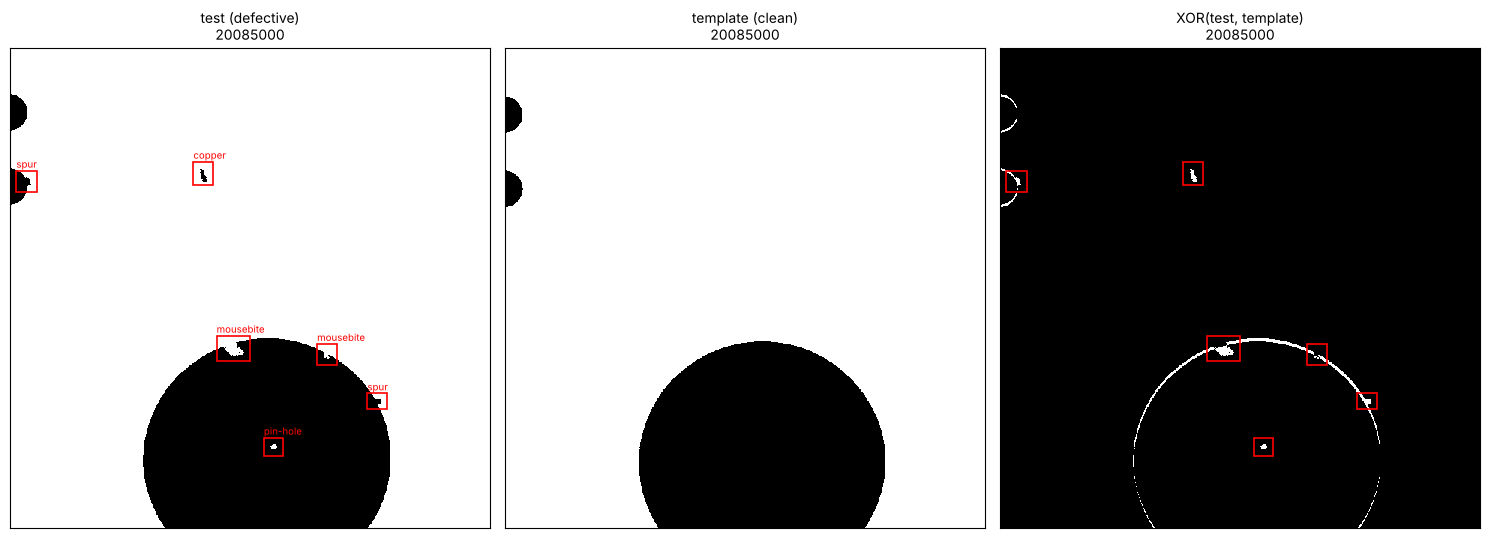

copper (white) covers 82.5% of the board
XOR fires on 0.569% of pixels -- the gate signal is sparse


In [4]:
import matplotlib.patches as patches

def show_pair(sample, ax_row=None):
    test, temp = sample.load()            # binarized {0,1}
    xor = test ^ temp
    axes = ax_row if ax_row is not None else plt.subplots(1, 3, figsize=(15, 5.4))[1]
    for ax, img, title in zip(axes, (test, temp, xor),
                              ('test (defective)', 'template (clean)', 'XOR(test, template)')):
        ax.imshow(img, cmap='gray', interpolation='nearest')
        ax.set_title(f'{title}\n{sample.name}', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    for x1, y1, x2, y2, cid in sample.boxes():
        for ax in (axes[0], axes[2]):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                           fill=False, edgecolor='red', lw=1.2))
        axes[0].text(x1, y1 - 4, deeppcb.CLASS_NAMES[cid], color='red', fontsize=7)
    return axes

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
show_pair(samples[0], axes)
plt.tight_layout(); plt.show()

test, temp = samples[0].load()
print(f'copper (white) covers {100 * test.mean():.1f}% of the board')
print(f'XOR fires on {100 * (test ^ temp).mean():.3f}% of pixels -- the gate signal is sparse')

## 2. Defect-size histogram per class

This is the measurement the tile geometry has to respect. A defect is only *findable* if some
tile holds at least `POS_THRESH` of its area, so the tail of this distribution sets the
required overlap.

In [5]:
boxes = grid_sweep.collect_boxes(samples)       # (M, 6): x1,y1,x2,y2,class_id,image_idx
w = boxes[:, 2] - boxes[:, 0]
h = boxes[:, 3] - boxes[:, 1]
maxdim = np.maximum(w, h)
print(f'{len(boxes)} defects over {len(samples)} images '
      f'({len(boxes)/len(samples):.2f} per image)\n')
print(grid_sweep.box_stats(boxes))

10013 defects over 1500 images (6.68 per image)

defect box sizes (max of width/height, pixels):
  class            n   mean   p50   p90   p99   max
  open          1942   48.4    41    77   121   167
  short         1506   53.0    48    80   115   173
  mousebite     1965   37.0    35    46    67   106
  spur          1625   37.1    36    45    61   140
  copper        1474   40.8    39    52    78   142
  pin-hole      1501   37.5    36    48    68   138
  ALL          10013   42.3    38    58   101   173


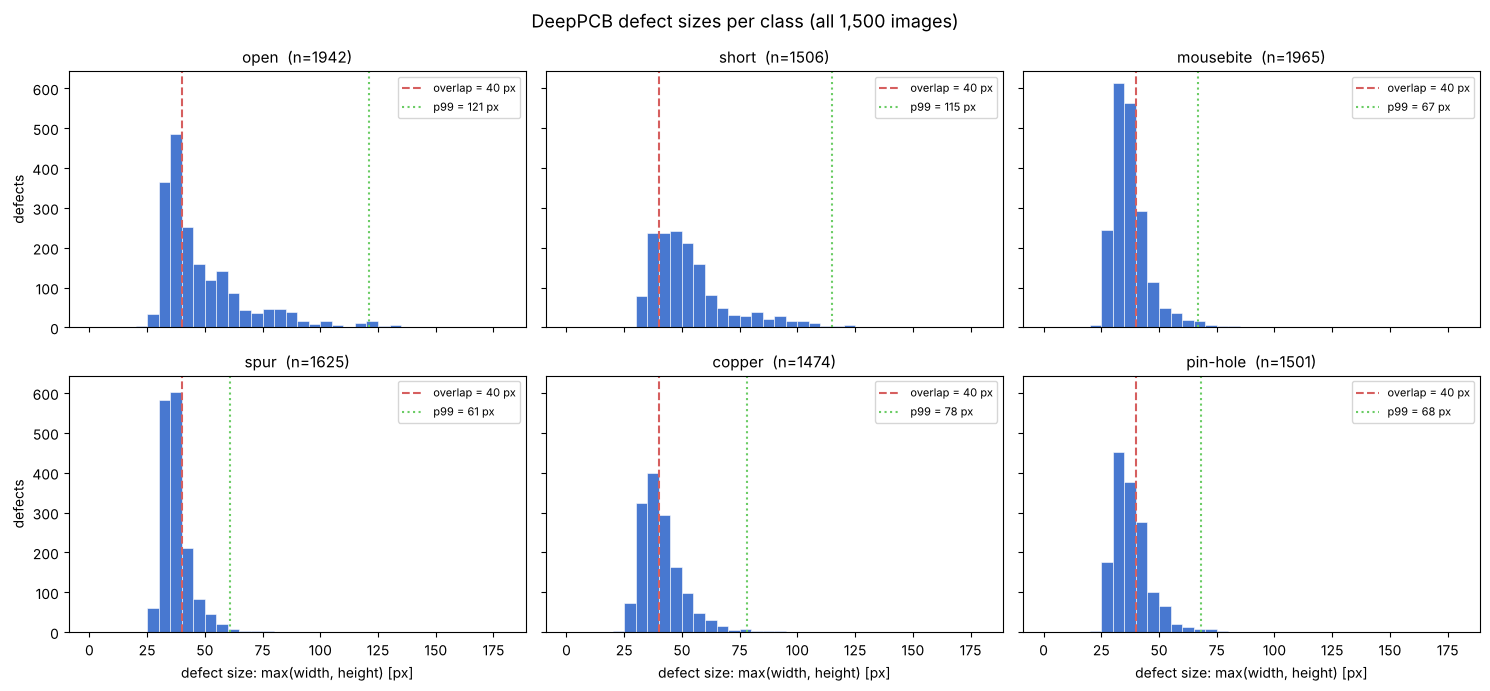

saved eval/figures/defect_size_hist.png


In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
bins = np.arange(0, 185, 5)
for ax, cid in zip(axs.ravel(), deeppcb.CLASS_IDS):
    m = maxdim[boxes[:, 4] == cid]
    ax.hist(m, bins=bins, color='#4878d0', edgecolor='white', linewidth=0.4)
    ax.axvline(GRID.overlap, color='#d65f5f', ls='--', lw=1.5,
               label=f'overlap = {GRID.overlap} px')
    ax.axvline(np.percentile(m, 99), color='#6acc64', ls=':', lw=1.5,
               label=f'p99 = {np.percentile(m, 99):.0f} px')
    ax.set_title(f'{deeppcb.CLASS_NAMES[cid]}  (n={len(m)})', fontsize=11)
    ax.legend(fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel('defect size: max(width, height) [px]')
for ax in axs[:, 0]:
    ax.set_ylabel('defects')
fig.suptitle('DeepPCB defect sizes per class (all 1,500 images)', fontsize=13)
plt.tight_layout(); plt.show()

os.makedirs('eval/figures', exist_ok=True)
fig.savefig('eval/figures/defect_size_hist.png', dpi=150, bbox_inches='tight')
print('saved eval/figures/defect_size_hist.png')

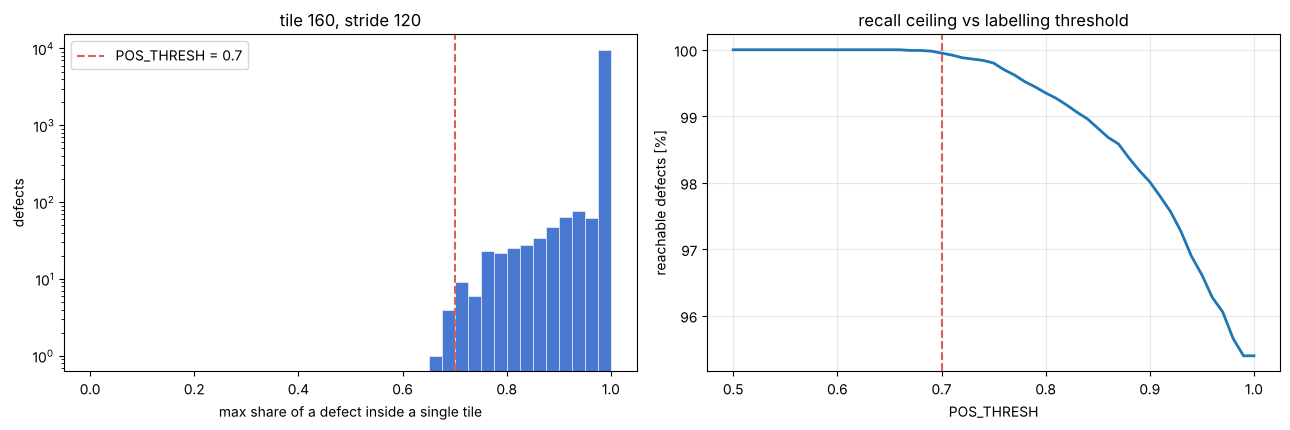

unreachable at POS_THRESH=0.7: 5/10013 (0.050%) -> recall ceiling 99.95%
they are the largest defects: [121, 123, 126, 151, 173] -> ['short', 'short', 'open', 'open', 'open']


In [7]:
# How much of each defect does the best tile actually hold?
best = box_overlap_fracs(boxes, GRID.tiles()).max(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
ax1.hist(best, bins=np.linspace(0, 1, 41), color='#4878d0', edgecolor='white', linewidth=0.4)
ax1.axvline(POS_THRESH, color='#d65f5f', ls='--', label=f'POS_THRESH = {POS_THRESH}')
ax1.set_xlabel('max share of a defect inside a single tile'); ax1.set_ylabel('defects')
ax1.set_yscale('log'); ax1.legend(); ax1.set_title(f'tile {TILE}, stride {STRIDE}')

ths = np.linspace(0.5, 1.0, 51)
ax2.plot(ths, [100 * (best >= t).mean() for t in ths], lw=2)
ax2.axvline(POS_THRESH, color='#d65f5f', ls='--')
ax2.set_xlabel('POS_THRESH'); ax2.set_ylabel('reachable defects [%]')
ax2.set_title('recall ceiling vs labelling threshold'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

unreachable = int((best < POS_THRESH).sum())
print(f'unreachable at POS_THRESH={POS_THRESH}: {unreachable}/{len(best)} '
      f'({100*unreachable/len(best):.3f}%) -> recall ceiling {100*(1-unreachable/len(best)):.2f}%')
if unreachable:
    big = maxdim[best < POS_THRESH]
    print('they are the largest defects:', sorted(big.tolist()),
          '->', [deeppcb.CLASS_NAMES[c] for c in boxes[best < POS_THRESH, 4]])

## 3. Which tile grid?

`reach` is the hard ceiling on defect-level recall, `clean` is the share of tiles the Stage-1
gate could skip, and `px cost` is what Stage 2 pays per board with the gate off. Overlap buys
reachability and costs compute.

In [8]:
rows = [grid_sweep.evaluate_grid(boxes, samples, TileGrid(t, s), POS_THRESH)
        for t, s in grid_sweep.DEFAULT_CANDIDATES]
print(grid_sweep.format_table(rows, POS_THRESH))

 tile/stride    grid  ovl  tiles  px cost  reach@0.70    full   clean    pos    ign
-----------------------------------------------------------------------------------
     128/128     5x5    0     25    1.00x     78.76%   53.9%   66.6%  20.6%  17.4%
     160/160     4x4    0     16    1.00x     82.37%   62.6%   56.8%  30.8%  19.6%
     160/120     5x5   40     25    1.56x     99.95%   95.4%   53.8%  32.0%  22.3%
      160/96     6x6   64     36    2.25x     99.99%   98.7%   52.2%  33.5%  22.6%
      160/80     7x7   80     49    3.06x    100.00%   99.3%   51.6%  34.2%  22.9%
     192/112     5x5   80     25    2.25x    100.00%   99.6%   42.1%  44.9%  26.7%
      192/96     6x6   96     36    3.24x    100.00%   99.8%   41.3%  45.5%  26.9%
     224/104     5x5  120     25    3.06x    100.00%  100.0%   32.6%  57.2%  28.3%
      256/96     5x5  160     25    4.00x    100.00%  100.0%   23.7%  67.9%  30.5%


## 4. Build the labelled tile dataset

One `.npz` with bit-packed whole images plus per-tile targets and ignore masks.
The split is by **image**: tiles overlap by 40 px, so splitting at tile level would leak.

In [9]:
npz_path = build_tiles.build(
    root=DATA_ROOT, out_dir=OUT_DIR, grid=GRID,
    pos_thresh=POS_THRESH, ignore_thresh=IGNORE_THRESH,
    val_frac=VAL_FRAC, seed=SEED, split_by=SPLIT_BY,
)

  200/1500 images (0s)


  400/1500 images (1s)


  600/1500 images (1s)


  800/1500 images (2s)


  1000/1500 images (2s)


  1200/1500 images (3s)


  1400/1500 images (3s)


  1500/1500 images (3s)



wrote data/tiles/deeppcb_tiles_t160_s120.npz  (10 MB)

tile=160 stride=120 overlap=40 grid=5x5 (25 tiles) pixel_cost=1.56x image
  fold  images   tiles   clean    pos    ign
 train     800   20000   52.9%  30.7%  25.1%
   val     200    5000   53.1%  30.6%  25.1%
  test     500   12500   54.6%  29.9%  22.6%

positive tiles per class (train / val / test):
  open          1334 /    339 /    886
  short         1058 /    261 /    624
  mousebite     1508 /    361 /    816
  spur          1278 /    323 /    677
  copper        1110 /    300 /    664
  pin-hole      1138 /    266 /    667


In [10]:
train = TileData.load(npz_path, 'train')
val   = TileData.load(npz_path, 'val')
test_ = TileData.load(npz_path, 'test')

for name, d in (('train', train), ('val', val), ('test', test_)):
    clean = is_clean(d.y.reshape(-1, 6), d.ignore.reshape(-1, 6))
    print(f'{name:>5}: {len(d):>4} images  {d.y.size // 6:>6} tiles  '
          f'{100*clean.mean():.1f}% clean')

print('\nno image appears in two folds:',
      not (set(train.names) & set(val.names)) and not (set(train.names) & set(test_.names)))
print('inverse-frequency positive weights (for the weighted BCE):')
for n, wt in zip(train.meta['class_names'], train.class_pos_weights()):
    print(f'  {n:<12}{wt:6.1f}')

train:  800 images   20000 tiles  52.9% clean
  val:  200 images    5000 tiles  53.1% clean
 test:  500 images   12500 tiles  54.6% clean

no image appears in two folds: True
inverse-frequency positive weights (for the weighted BCE):
  open          13.1
  short         17.0
  mousebite     11.6
  spur          14.0
  copper        16.2
  pin-hole      15.8


### Sanity-check the tile labels

Green border = positive for some class, orange = fragment only (ignored), grey = clean.
The tile grid must line up with the boxes, and a defect straddling two tiles must be positive
in the one that holds it and ignored in the other.

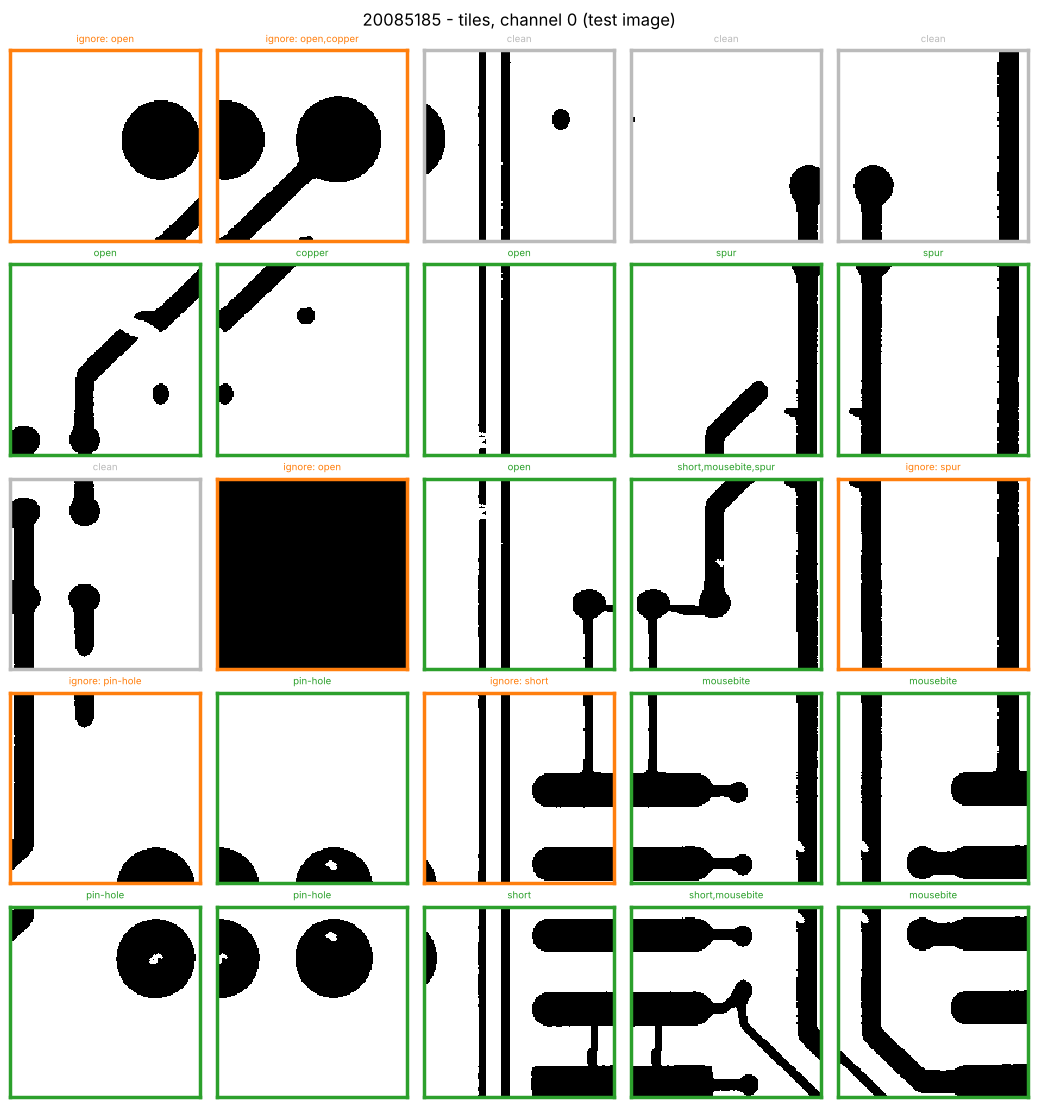

In [11]:
def show_tile_labels(d, i, representation='C'):
    x, y, ign = d.tiles(i, representation)
    rows, cols = d.grid.grid_shape
    fig, axs = plt.subplots(rows, cols, figsize=(2.1 * cols, 2.25 * rows))
    for k, ax in enumerate(axs.ravel()):
        ax.imshow(x[k, 0], cmap='gray', interpolation='nearest')
        ax.set_xticks([]); ax.set_yticks([])
        pos = [n for n, v in zip(d.meta['class_names'], y[k]) if v > 0]
        frg = [n for n, v in zip(d.meta['class_names'], ign[k]) if v]
        colour, label = '#bbbbbb', 'clean'
        if pos:
            colour, label = '#2ca02c', ','.join(pos)
        elif frg:
            colour, label = '#ff7f0e', 'ignore: ' + ','.join(frg)
        for sp in ax.spines.values():
            sp.set_color(colour); sp.set_linewidth(2.5)
        ax.set_title(label, fontsize=7, color=colour)
    fig.suptitle(f'{d.names[i]} - tiles, channel 0 (test image)', fontsize=12)
    plt.tight_layout(); plt.show()

idx = int(np.argmax((val.y > 0).any(-1).sum(-1)))   # the busiest image in val
show_tile_labels(val, idx)

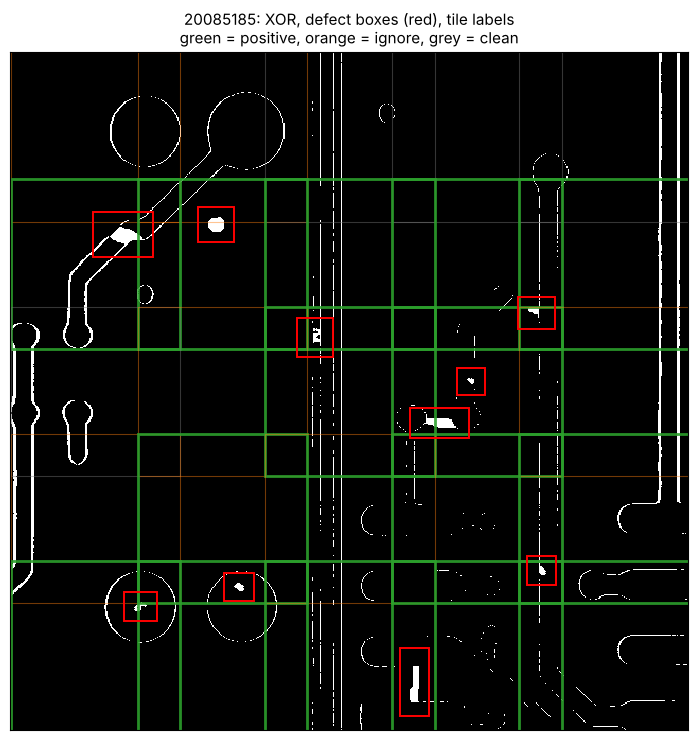

In [12]:
# The same labels, drawn back onto the whole board, so grid alignment is easy to eyeball.
x1s, y1s = val.grid.origins_1d, val.grid.origins_1d
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(val.test[idx] ^ val.temp[idx], cmap='gray', interpolation='nearest')
for k, (tx1, ty1, tx2, ty2) in enumerate(val.grid.tiles()):
    pos = (val.y[idx, k] > 0).any()
    ign = val.ignore[idx, k].any()
    colour = '#2ca02c' if pos else ('#ff7f0e' if ign else '#777777')
    ax.add_patch(patches.Rectangle((tx1, ty1), tx2 - tx1, ty2 - ty1, fill=False,
                                   edgecolor=colour, lw=2 if pos else 0.8,
                                   alpha=0.9 if pos else 0.45))
for bx1, by1, bx2, by2, cid in val.boxes[idx]:
    ax.add_patch(patches.Rectangle((bx1, by1), bx2 - bx1, by2 - by1,
                                   fill=False, edgecolor='red', lw=1.4))
ax.set_title(f'{val.names[idx]}: XOR, defect boxes (red), tile labels\n'
             'green = positive, orange = ignore, grey = clean', fontsize=11)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Augmentation

Flips and 90-degree rotations are applied to both images, and the labels are recomputed from the
transformed boxes rather than transformed themselves. The misalignment shift moves the
**template only**, which is the one augmentation that deliberately breaks the pair's alignment -
watch what it does to the XOR channel that Stage 1 depends on.

AugmentConfig(flip=True, rot90=True, max_shift=3, morph_prob=0.3, morph_radius=1)


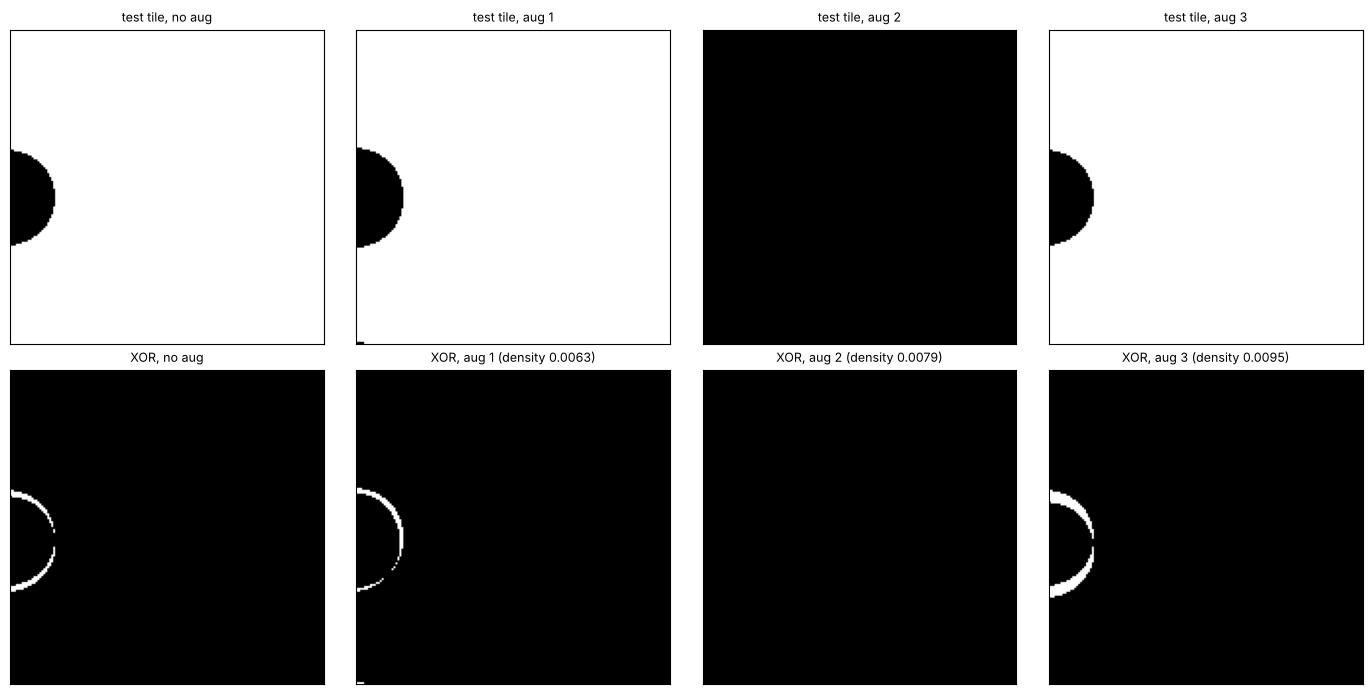

positive tiles, no aug: 7; under 8 augmentations: [7, 7, 7, 7, 7, 7, 7, 7]
XOR density  no aug 0.0061  |  with misalignment 0.0068 (min 0.0033, max 0.0098)
Misalignment inflates the XOR mask, which is why Stage 1 cannot just count raw XOR
pixels. Run `python eval/gate_analysis.py` for the measured cost: raw XOR separates
clean from defective tiles at only AUC 0.78, and a 5x5 erosion of the mask first
raises that to 0.92 while staying above 0.89 at +-3 px misalignment.


In [13]:
aug = AugmentConfig.train_default()
print(aug)
rng = np.random.default_rng(SEED)

x_clean, y_clean, _ = train.tiles(0, 'C')
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
axs[0, 0].imshow(x_clean[0, 0], cmap='gray'); axs[0, 0].set_title('test tile, no aug', fontsize=9)
axs[1, 0].imshow(x_clean[0, 1], cmap='gray'); axs[1, 0].set_title('XOR, no aug', fontsize=9)
for j in range(1, 4):
    xa, ya, iga = train.tiles(0, 'C', aug, rng)
    axs[0, j].imshow(xa[0, 0], cmap='gray'); axs[0, j].set_title(f'test tile, aug {j}', fontsize=9)
    axs[1, j].imshow(xa[0, 1], cmap='gray')
    axs[1, j].set_title(f'XOR, aug {j} (density {xa[:, 1].mean():.4f})', fontsize=9)
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

# Labels must stay consistent under augmentation: the same defects are present,
# so the number of positive tiles should not change (only their positions).
n_pos_clean = int((y_clean > 0).any(-1).sum())
n_pos_aug = [int((train.tiles(0, 'C', aug, rng)[1] > 0).any(-1).sum()) for _ in range(8)]
print(f'positive tiles, no aug: {n_pos_clean}; under 8 augmentations: {n_pos_aug}')

dens = [train.tiles(0, 'C', aug, rng)[0][:, 1].mean() for _ in range(10)]
print(f'XOR density  no aug {x_clean[:, 1].mean():.4f}  |  with misalignment '
      f'{np.mean(dens):.4f} (min {min(dens):.4f}, max {max(dens):.4f})')
print('Misalignment inflates the XOR mask, which is why Stage 1 cannot just count raw XOR\n'
      'pixels. Run `python eval/gate_analysis.py` for the measured cost: raw XOR separates\n'
      'clean from defective tiles at only AUC 0.78, and a 5x5 erosion of the mask first\n'
      'raises that to 0.92 while staying above 0.89 at +-3 px misalignment.')

## Next steps

* `python eval/gate_analysis.py` - how separable clean and defective tiles are by XOR count,
  and what misalignment does to that (sets up the Stage-1 gate and the key energy/recall figure).
* `training/` - teacher (ResNet-18, 2-channel) and the control student.
* `firmware/` - get a dummy model running on the XIAO ESP32-S3 to de-risk the toolchain.

The built `.npz` is ~10 MB. Cache it on Drive and later notebooks can load it directly with
`TileData.load(path, fold)` instead of re-downloading DeepPCB.